<a href="https://colab.research.google.com/github/vlasceanuadriana/ML-Seminar-VlasceanuAdriana/blob/main/Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [2]:
# TODO 1.1 — procentul de valori lipsă pe coloană
(df.isna().mean()*100).round(2).sort_values(ascending=False)


,0
deck,77.22
age,19.87
embarked,0.22
sex,0.00
pclass,0.00
survived,0.00
fare,0.00


In [3]:
# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
missing_precent=df.isna().mean()*100
columns_to_drop=missing_precent[missing_precent>50].index
df=df.drop(columns=columns_to_drop)
df.head()

,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [8]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()

df['age']=df['age'].fillna(df['age'].median())
df['embarked']=df['embarked'].fillna(df['embarked'].mode()[0])

# TODO 2.2 — verificare + comparație deviație standard
print('Valori lipsa: ')
print(df.isna().sum())
print(" ")
print('Deviataia standard age inainte: ', round(age_inainte.std(),4))
print('Deviataia standard age dupa: ', round(df['age'].std(),4))


Valori lipsa: 
survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64
 
Deviataia standard age inainte:  13.0197
Deviataia standard age dupa:  13.0197


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness: 4.787316519674893
Skewness log_fare: 0.3949280095189306


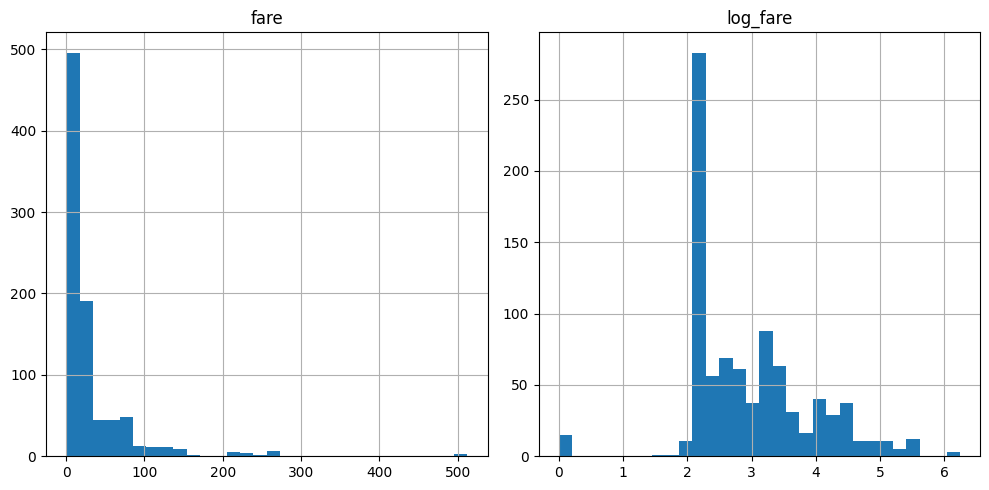

In [10]:
# TODO 3.1 — skewness fare
print('Skewness:', df['fare'].skew())

# TODO 3.2 — coloana log_fare + skewness
df['log_fare']=np.log1p(df['fare'])
print('Skewness log_fare:',df['log_fare'].skew())

# TODO 3.3 — două histograme
df[['fare','log_fare']].hist(bins=30,figsize=(10,5))
plt.tight_layout()
plt.show()

In [ ]:
#După transformarea logaritmică, coeficientul de asimetrie al variabilei log_fare scade la 0,39. Transformarea a ajutat,
#deoarece distribuția a devenit mult mai puțin asimetrică și mai apropiată de una simetrică.

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [12]:
# TODO 4.1 — limite IQR + număr de outlieri
def limite_iqr(serie, k=1.5):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

jos, sus = limite_iqr(df['fare'])

n_out = ((df['fare'] < jos) | (df['fare'] > sus)).sum()

print("Limita inferioară:", round(jos, 2))
print("Limita superioară:", round(sus, 2))
print("Număr outlieri:", n_out)


# TODO 4.2 — fare_capped (clip) + maxim înainte/după
df['fare_capped'] = df['fare'].clip(lower=jos, upper=sus)

print("Maxim înainte:", df['fare'].max())
print("Maxim după:", df['fare_capped'].max())

Limita inferioară: -26.72
Limita superioară: 65.63
Număr outlieri: 116
Maxim înainte: 512.3292
Maxim după: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [13]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df = pd.get_dummies(df, columns=['sex', 'embarked'],
                    drop_first=True, dtype=int)

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scaler = StandardScaler()

df[['age_scaled', 'fare_capped_scaled']] = scaler.fit_transform(
    df[['age', 'fare_capped']]
)

print("Medii:")
print(df[['age_scaled', 'fare_capped_scaled']].mean())

print("\nDeviații standard:")
print(df[['age_scaled', 'fare_capped_scaled']].std(ddof=0))

Medii:
age_scaled            2.272780e-16
fare_capped_scaled    9.968332e-17
dtype: float64

Deviații standard:
age_scaled            1.0
fare_capped_scaled    1.0
dtype: float64


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

Răspunsul tău: Am imputat age cu mediana deoarece este o variabilă numerică și mediana nu este influențată puternic de valorile extreme. În schimb, am eliminat deck deoarece avea peste 50% valori lipsă, iar eliminarea acestei coloane a fost mai potrivită decât înlocuirea unui număr atât de mare de valori necunoscute.
